# 05c — 24-hour landmark severity sensitivity

## Summary

Explore first-day severity in admissions alive and still hospitalized beyond 24 hours after ICU entry. Reset follow-up at that landmark and compare age/sex and SOFA-core models on the same complete cases. This changes the population and estimand. Published clinical tables and a forest plot appear below without execution; the separate runtime demonstration defaults to synthetic data.

<!-- Generated public landmark summary: intro; edit scripts/render_landmark_summary.py -->

## Saved clinical results

The tables and figures in this section display saved clinical execution results from [the public aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json). They do not represent a new clinical rerun. The separately labeled execution section describes how to reproduce outputs. Any synthetic execution is explicitly labeled and is not a clinical MIMIC result.

<!-- Generated public landmark summary: eligibility; edit scripts/render_landmark_summary.py -->

### Cohort at the 24-hour landmark

| Eligibility step | Admissions |
| --- | ---: |
| Original ICU-entry cohort | 11,964 |
| Excluded: death at or before 24 hours | 254 |
| Excluded: live discharge at or before 24 hours | 178 |
| Excluded: remaining death with unknown death time | 2 |
| Eligible: alive and hospitalized beyond 24 hours | 11,530 |
| Excluded: missing core covariates among eligible admissions | 0 |
| Analyzed in each matched landmark model | 11,530 |

Exclusions are sequential. Follow-up starts 24 hours after ICU entry; one day is subtracted from eligible follow-up. Both models use the same 11,530 admissions (8,854 patients).

<!-- Generated public landmark summary: models; edit scripts/render_landmark_summary.py -->

### Matched landmark Cox results

The contrast is qualifying pre-ICU RAAS prescription orders versus no qualifying orders. Both models stratify by era; all intervals and p-values below use patient-cluster inference.

| Model | Admissions | Deaths | Adjusted HR | Patient-cluster 95% CI | p |
| --- | ---: | ---: | ---: | --- | ---: |
| Age/sex/era | 11,530 | 1,436 | 0.771 | 0.617–0.965 | 0.02313 |
| Exploratory SOFA core | 11,530 | 1,436 | 0.854 | 0.673–1.082 | 0.19133 |

<!-- Generated public landmark summary: figure; edit scripts/render_landmark_summary.py -->

### Figure 1 — 24-hour landmark Cox models

**Data source:** Saved clinical execution results; [aggregate record](../docs/SURVIVAL_SENSITIVITY_RESULTS.json).

![Figure 1 — 24-hour landmark Cox models](../assets/supplementary_landmark_forest.png)

**How to read**

- Each blue dot is the adjusted hazard ratio for qualifying pre-ICU RAAS orders versus no qualifying orders. Each horizontal line is its patient-cluster 95% confidence interval; it is not a distribution of patient outcomes.
- The dashed line at HR=1 represents equal hazards under the fitted model. Points to its left indicate a lower estimated death hazard, and points to its right indicate a higher estimated hazard. This is a hazard comparison, not an absolute mortality probability. The horizontal axis uses a logarithmic scale.
- The first row adjusts for age and sex with era strata. The second additionally includes first-day SOFA, CHF, CKD and diabetes. Both use the same 11,530 admissions alive and hospitalized beyond 24 hours, with follow-up beginning at that landmark.

**What the results show**

- Age/sex/era: HR 0.771 (95% CI 0.617–0.965). The interval lies below 1, indicating an association with lower death hazard under this specification.
- Exploratory SOFA core: HR 0.854 (95% CI 0.673–1.082). The estimate is closer to 1, and its interval includes 1. This result remains compatible with lower, equal or somewhat higher hazard; it does not establish absence of an association or equivalence.

**Interpretation limits**

The two rows are different adjustment specifications, not separate treatment groups or a formal test between model estimates. One interval excluding 1 and the other including 1 does not establish a statistically significant difference between the estimates. Their change cannot be attributed solely to controlling baseline severity: first-day SOFA is post-exposure, and individual component times remain independently unverified. The landmark also changes the population and time origin relative to the original ICU-entry analysis. Neither row establishes a causal treatment effect.

## Context & Methods

Fix the landmark at 24 elapsed hours from the original ICU entry. Exclude death/discharge endpoints at or before it. Also exclude remaining deaths with missing death timestamps because their true survival to the landmark is unknown. Preserve the original pre-ICU prescription-order classification, subtract one day from eligible durations, and use era strata and patient-cluster Efron Cox inference.

### Key assumptions
- The published `first_day_sofa` definition uses measurements through ICU entry plus one day. The deployed component windows and individual measurement times have not been independently reconstructed.
- This is a conditional landmark sensitivity analysis, not a reconstruction of pre-ICU baseline severity.
- First-day SOFA follows exposure and can mediate associations or introduce selection/collider bias. Landmarking does not establish causality.
- Keep CHF, CKD and diabetes definitions from the original core model; their diagnosis timing is not newly validated.
- Use identical core-complete admissions for both landmark fits; report excluded early endpoints and missingness.

## Data

Run from the repository root or `notebooks/` after `uv sync --locked`. The existing bounded BigQuery loader is used only for explicit `current` mode. Pseudonymous keys stay in memory; never print source rows. Use `local` mode to inspect a previously verified aggregate run without another query.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from survival_sensitivity import run_supplement, load_local_bundle, plot_supplement
%matplotlib inline
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

In [2]:
# Default is synthetic; the verified clinical rerun sets COPD_NOTEBOOK_DATA_MODE=current.
# Never display a patient-level DataFrame.
import os, json
DATA_MODE = os.environ.get("COPD_NOTEBOOK_DATA_MODE", "synthetic")  # synthetic, current, local
LOCAL_RESULT = REPO_ROOT / "reports/local_supplements/sensitivity_run02/aggregate_results.json"
BOOTSTRAP_REPLICATES = 1000 if DATA_MODE == "current" else 200

if DATA_MODE == "local":
    bundle = load_local_bundle(LOCAL_RESULT, REPO_ROOT, "landmark")
elif DATA_MODE in {"synthetic", "current"}:
    bundle = run_supplement("landmark", repo=REPO_ROOT, clinical=DATA_MODE == "current",
                            bootstrap_replicates=BOOTSTRAP_REPLICATES)
else:
    raise ValueError("Unknown DATA_MODE")
result = bundle["results"]["landmark"]
print({"data_origin": bundle["data_origin"], "supplement_version": bundle["supplement_version"],
       "main_analysis_updated": bundle["main_analysis_updated"]})
# Retain only the aggregate execution bundle under the ignored run directory.
if os.environ.get("COPD_NOTEBOOK_RUN_DIR"):
    aggregate_output = Path(os.environ["COPD_NOTEBOOK_RUN_DIR"]) / "supplement_bundle.json"
    aggregate_output.parent.mkdir(parents=True, exist_ok=True)
    aggregate_output.write_text(json.dumps(bundle, indent=2, allow_nan=False) + "\n")


{'data_origin': 'authorized_local_current_cohort', 'supplement_version': 'patient_cluster_competing_landmark_v1', 'main_analysis_updated': False}


## Runtime execution

The data-origin label above controls these execution outputs. The committed outputs were generated with current clinical data in the [verified full rerun](../docs/NOTEBOOK_EXECUTION_VALIDATION.json). A new execution defaults to synthetic inputs unless current mode is selected. Synthetic outputs validate software execution only. Figure 1 above remains the fixed published aggregate snapshot.

### Eligibility and exclusions

In [3]:
display(pd.DataFrame(result["eligibility"].items(), columns=["Eligibility measure", "Admissions / days"]))

,Eligibility measure,Admissions / days
0,original_admissions,11964.0
1,landmark_days,1.0
2,deaths_at_or_before_landmark,254.0
3,discharges_at_or_before_landmark,178.0
4,additional_fallback_deaths_excluded,2.0
5,eligible_alive_and_hospitalized,11530.0
6,eligible_missing_core_covariates,0.0


### Matched landmark models

In [4]:
rows = []
for name, model in result["models"].items():
    e = model["estimates"]["raas_pre_icu"]
    rows.append({"Model": name, "Admissions": model["n"], "Patients": model["patients"],
                 "RAAS HR": e["hr"],
                 "Ordinary 95% CI": f"{e['ordinary']['lower_95']:.3f}–{e['ordinary']['upper_95']:.3f}",
                 "Cluster 95% CI": f"{e['patient_cluster']['lower_95']:.3f}–{e['patient_cluster']['upper_95']:.3f}",
                 "Ordinary p": e["ordinary"]["p"], "Cluster p": e["patient_cluster"]["p"]})
display(pd.DataFrame(rows).style.format({"RAAS HR": "{:.3f}", "Ordinary p": "{:.4g}", "Cluster p": "{:.4g}"}))

,Model,Admissions,Patients,RAAS HR,Ordinary 95% CI,Cluster 95% CI,Ordinary p,Cluster p
0,landmark_age_sex,11530,8854,0.771,0.615–0.967,0.617–0.965,0.02447,0.02313
1,landmark_first_day_sofa_core,11530,8854,0.854,0.680–1.071,0.673–1.082,0.1712,0.1913


### Figure 2 — Ordinary and patient-cluster inference (selected execution)

**Data source:** Selected execution input; check the printed `data_origin` and plot title. Synthetic execution is a software demonstration, not a clinical MIMIC result.

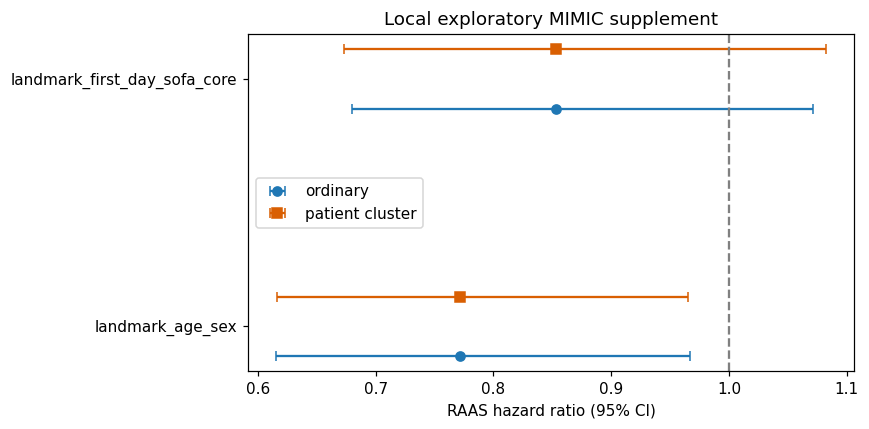

In [5]:
ANALYSIS = "landmark"
figure = plot_supplement(bundle, ANALYSIS)
display(figure)
plt.close(figure)

**How to read**

- `landmark_age_sex` is the age/sex model with era strata. `landmark_first_day_sofa_core` additionally includes first-day SOFA, CHF, CKD and diabetes. Use the row labels to identify the models; this runtime plot uses its own row order and a linear horizontal scale.
- **Blue circles** show ordinary admission-level 95% intervals; **orange squares** show patient-cluster 95% intervals. The colors distinguish uncertainty methods, not RAAS-exposed and unexposed groups. Each horizontal bar is a confidence interval.

**What the results show**

- Within one model, the two methods share the same fitted RAAS HR. Their vertical offsets only separate the symbols visually. Only the uncertainty calculation changes; clustering allows dependence among repeated admissions from the same patient. A cluster interval can be wider or narrower, so clustering does not guarantee a particular p-value change.

**Interpretation limits**

- Read the title and the `data_origin` printed for this execution first. If the title says **SYNTHETIC demonstration**, the numerical values are artificial software examples, not MIMIC findings. The saved clinical estimates are in Figure 1 above.
- The dashed line is HR=1. An interval crossing it does not establish equal hazards or absence of an association. This plot compares variance methods within each model; it is not an independent clinical validation or a causal treatment comparison.

## Takeaways

Compare the two landmark models within their matched eligible cohort. Differences from the original ICU-entry analysis combine selection, a later risk origin and adjustment changes; they cannot isolate a baseline severity effect. A pre-ICU measurement-based severity design remains a separate analysis.

See [the supplement guide](../docs/SURVIVAL_SENSITIVITY_SUPPLEMENTS.md) for the execution commands, data handling, reference checks and limitations. Tracked notebooks retain only the reviewed aggregate outputs bound in [the execution record](../docs/NOTEBOOK_EXECUTION_VALIDATION.json); full local result bundles stay under ignored `reports/local_supplements/`.